---------------------------------------------
   RESULTADO: 53.00 minutos.
---------------------------------------------


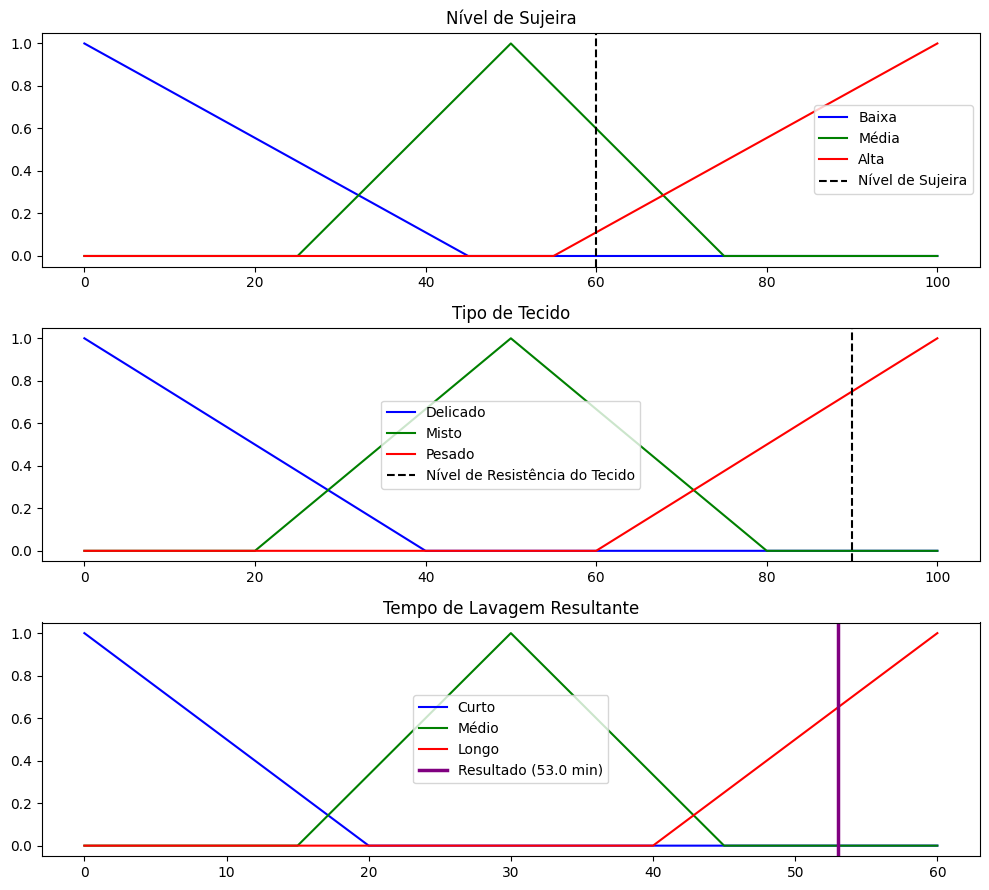

In [ ]:
!pip install scikit-fuzzy -q
import numpy as np
import skfuzzy as fuzzy
from skfuzzy import control as ctrl
import matplotlib.pyplot as plt

sensor_sujeira = np.arange(0, 101, 1)
sensor_tecido = np.arange(0, 101, 1)
escala_tempo = np.arange(0, 61, 1)

sujeira = ctrl.Antecedent(sensor_sujeira, 'sujeira') #entrada crisp
tecido = ctrl.Antecedent(sensor_tecido, 'tecido') #entrada crisp
tempo_lavagem = ctrl.Consequent(escala_tempo, 'tempo_lavagem')

#fuzzificação
sujeira['baixa'] = fuzzy.trimf(sensor_sujeira, [0, 0, 45]) #função de pertinência
sujeira['media'] = fuzzy.trimf(sensor_sujeira, [25, 50, 75])
sujeira['alta'] = fuzzy.trimf(sensor_sujeira, [55, 100, 100])

tecido['delicado'] = fuzzy.trimf(sensor_tecido, [0, 0, 40])
tecido['misto'] = fuzzy.trimf(sensor_tecido, [20, 50, 80])
tecido['pesado'] = fuzzy.trimf(sensor_tecido, [60, 100, 100])

tempo_lavagem['curto'] = fuzzy.trimf(escala_tempo, [0, 0, 20])
tempo_lavagem['medio'] = fuzzy.trimf(escala_tempo, [15, 30, 45])
tempo_lavagem['longo'] = fuzzy.trimf(escala_tempo, [40, 60, 60])

regra1 = ctrl.Rule(sujeira['baixa'] & tecido['delicado'], tempo_lavagem['curto']) #extração dos graus de pertinência e aplicação na regra de inferência
regra2 = ctrl.Rule(sujeira['media'] & tecido['misto'], tempo_lavagem['medio'])
regra3 = ctrl.Rule(sujeira['alta'] | tecido['pesado'], tempo_lavagem['longo'])
regra4 = ctrl.Rule(sujeira['baixa'] & tecido['pesado'], tempo_lavagem['medio'])

sistema_controle = ctrl.ControlSystem([regra1, regra2, regra3, regra4]) #agregação das regras
maquina_lavar = ctrl.ControlSystemSimulation(sistema_controle) #decisão fuzzy antes de ir para a defuzzificação

#valores de teste (leitura dos sensores)
VALOR_SUJEIRA = 60
VALOR_TECIDO = 90

maquina_lavar.input['sujeira'] = VALOR_SUJEIRA
maquina_lavar.input['tecido'] = VALOR_TECIDO
maquina_lavar.compute() #defuzzificação
resultado_tempo = maquina_lavar.output['tempo_lavagem'] #extração do resultado em valor crisp

print("-" * 45)
print(f"   RESULTADO: {resultado_tempo:.2f} minutos.")
print("-" * 45)

#gráficos
fig, (grafico_sujeira, grafico_tecido, grafico_tempo) = plt.subplots(nrows=3, figsize=(10, 9))

grafico_sujeira.plot(sensor_sujeira, sujeira['baixa'].mf, 'b', label='Baixa')
grafico_sujeira.plot(sensor_sujeira, sujeira['media'].mf, 'g', label='Média')
grafico_sujeira.plot(sensor_sujeira, sujeira['alta'].mf, 'r', label='Alta')
grafico_sujeira.axvline(x=VALOR_SUJEIRA, color='black', linestyle='--', label='Nível de Sujeira')
grafico_sujeira.set_title('Nível de Sujeira')
grafico_sujeira.legend()

grafico_tecido.plot(sensor_tecido, tecido['delicado'].mf, 'b', label='Delicado')
grafico_tecido.plot(sensor_tecido, tecido['misto'].mf, 'g', label='Misto')
grafico_tecido.plot(sensor_tecido, tecido['pesado'].mf, 'r', label='Pesado')
grafico_tecido.axvline(x=VALOR_TECIDO, color='black', linestyle='--', label='Nível de Resistência do Tecido')
grafico_tecido.set_title('Tipo de Tecido')
grafico_tecido.legend()

grafico_tempo.plot(escala_tempo, tempo_lavagem['curto'].mf, 'b', label='Curto')
grafico_tempo.plot(escala_tempo, tempo_lavagem['medio'].mf, 'g', label='Médio')
grafico_tempo.plot(escala_tempo, tempo_lavagem['longo'].mf, 'r', label='Longo')
grafico_tempo.axvline(x=resultado_tempo, color='purple', linestyle='-', linewidth=2.5, label=f'Resultado ({resultado_tempo:.1f} min)')
grafico_tempo.set_title('Tempo de Lavagem Resultante')
grafico_tempo.legend()

plt.tight_layout()
plt.show()

In [ ]:
import ipywidgets as widgets
from IPython.display import display, HTML

#calcula tempo e atualiza painel através do modelo fuzzy da máquina
def atualizar_painel(sujeira_val, tecido_val):
    # Executa a lógica fuzzy implementada anteriormente
    maquina_lavar.input['sujeira'] = sujeira_val
    maquina_lavar.input['tecido'] = tecido_val
    maquina_lavar.compute()
    tempo_final = maquina_lavar.output['tempo_lavagem']

    #determina tipo de ciclo baseado no tempo calculado
    if tempo_final <= 20:
        modo = "Ciclo Rápido / Seda e Tule"
        cor_status = "#2196F3" #Azul
    elif tempo_final <= 42:
        modo = "Ciclo Geral / Algodão e Linho"
        cor_status = "#4CAF50" #Verde
    else:
        modo = "Ciclo Intenso / Jeans e Brim"
        cor_status = "#FF9800" #Vermelho

    #porcentagem de duração do ciclo (máximo 60 min)
    porcentagem_barra = (tempo_final / 60) * 100

    #html painel da máquina
    painel_html = f"""
    <div style="background-color: #2c3e50; border-radius: 15px; padding: 25px; width: 450px; font-family: 'Segoe UI', Tahoma, Geneva, Verdana, sans-serif; color: white; box-shadow: 0px 10px 20px rgba(0,0,0,0.3); margin: 20px auto;">

        <!-- topo do Painel -->
        <div style="display: flex; justify-content: space-between; align-items: center; border-bottom: 2px solid #34495e; padding-bottom: 10px; margin-bottom: 20px;">
            <span style="font-size: 12px; letter-spacing: 2px; color: #bdc3c7; font-weight: bold;">MÁQUINA DE LAVAR FUZZY</span>
            <div style="width: 12px; height: 12px; background-color: #2ecc71; border-radius: 50%; box-shadow: 0 0 10px #2ecc71;"></div>
        </div>

        <!-- display principal -->
        <div style="background-color: #0f141d; border: 3px solid #34495e; border-radius: 10px; padding: 20px; text-align: center; margin-bottom: 20px; position: relative;">
            <div style="font-size: 11px; color: #566573; position: absolute; top: 5px; left: 10px; letter-spacing: 1px;">TEMPO ESTIMADO</div>
            <div style="font-family: 'Courier New', Courier, monospace; font-size: 48px; color: #00ffcc; font-weight: bold; text-shadow: 0 0 15px rgba(0,255,204,0.6);">
                {tempo_final:.1f}<span style="font-size: 20px; color: #00ffcc; margin-left: 5px;">MIN</span>
            </div>
            <div style="font-size: 13px; color: {cor_status}; font-weight: bold; margin-top: 5px; letter-spacing: 1px;">
                ● {modo.upper()}
            </div>
        </div>

        <!-- leitura dos sensores -->
        <div style="display: flex; justify-content: space-between; margin-bottom: 20px; background-color: #34495e; padding: 10px; border-radius: 8px;">
            <div style="text-align: center; width: 50%;">
                <div style="font-size: 10px; color: #bdc3c7;">SENSOR SUJEIRA</div>
                <div style="font-size: 18px; font-weight: bold; color: #e74c3c;">{sujeira_val}%</div>
            </div>
            <div style="border-left: 1px solid #5d6d7e; height: 30px; margin-top: 5px;"></div>
            <div style="text-align: center; width: 50%;">
                <div style="font-size: 10px; color: #bdc3c7;">SENSOR TECIDO</div>
                <div style="font-size: 18px; font-weight: bold; color: #3498db;">{tecido_val}%</div>
            </div>
        </div>

        <!-- barra de duração do ciclo -->
        <div style="margin-bottom: 10px;">
            <div style="display: flex; justify-content: space-between; font-size: 11px; color: #bdc3c7; margin-bottom: 5px;">
                <span>Duração do Ciclo</span>
                <span>{porcentagem_barra:.0f}%</span>
            </div>
            <div style="background-color: #1a252f; border-radius: 10px; height: 12px; width: 100%; overflow: hidden;">
                <div style="background: linear-gradient(90deg, #00ffcc, {cor_status}); height: 100%; width: {porcentagem_barra}%; transition: width 0.3s ease;"></div>
            </div>
        </div>

    </div>
    """
    display(HTML(painel_html))

#controles do painel (simulando leituras dos sensores)
slider_sujeira = widgets.IntSlider(min=0, max=100, step=1, value=35, description='Sujeira:', style={'description_width': 'initial'})
slider_tecido = widgets.IntSlider(min=0, max=100, step=1, value=40, description='Resistência:', style={'description_width': 'initial'})

#controles posicionados acima do painel
controles = widgets.VBox([
    widgets.HTML("<b style='font-family:sans-serif; color:#2c3e50;'> SIMULADOR DE SENSORES DA MÁQUINA DE LAVAR:</b><br>"),
    slider_sujeira,
    slider_tecido
])

#ligação entre os sliders e a interface gráfica do painel (passagem dos parâmetros)
interface_painel = widgets.interactive_output(atualizar_painel, {'sujeira_val': slider_sujeira, 'tecido_val': slider_tecido})

# Renderiza tudo na tela do Colab
display(controles, interface_painel)

Output()